# EDA Proyecto

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotnine
import statsmodels.api as sm

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotnine

# cargar datos
from data import loader

df = loader.get_data()

print("DataFrame shape:", df.shape)
df.info()
df.describe()

## Factores


### Estadística descriptiva

Se calculan las medidas de tendencia central y dispersión del error absoluto para cada una de las seis combinaciones de distancia y tipo de pared.

In [ ]:
datosError = df.copy()
datosError["Error absoluto (mm)"] = datosError["Error con signo (mm)"].abs()

resumenDescriptivo = (
    datosError.groupby(["Distancia de referencia (mm)", "Tipo de pared"])["Error absoluto (mm)"]
    .agg(n="count", media="mean", mediana="median", desviacionEstandar="std", varianza="var", minimo="min", maximo="max")
    .reset_index()
    .rename(columns={
        "Distancia de referencia (mm)": "Distancia (mm)",
        "Tipo de pared": "Tipo de pared",
        "media": "Media (mm)",
        "mediana": "Mediana (mm)",
        "desviacionEstandar": "Desviación estándar (mm)",
        "varianza": "Varianza (mm²)",
        "minimo": "Mínimo (mm)",
        "maximo": "Máximo (mm)"
    })
    .sort_values(["Distancia (mm)", "Tipo de pared"])
    .reset_index(drop=True)
)

display(resumenDescriptivo.round(2))

Con la estadística descriptiva se puede observar que el error absoluto promedio aumenta conforme aumenta la distancia. A 100 milímetros los errores promedio son bajos para ambos tipos de pared, mientras que a 2500 milímetros se presentan los valores más altos. A 1000 milímetros la pared brillante presenta un error promedio mayor que la mate, mientras que a 2500 milímetros sucede lo contrario. Estas diferencias se analizan de forma exploratoria.

In [ ]:
# datos divididos por tipo de pared
datos_mate = (
    df.loc[df["Tipo de pared"].eq("Mate"), "Error con signo (mm)"]
)
datos_brillante = (
    df.loc[df["Tipo de pared"].eq("Brillante"), "Error con signo (mm)"]
)

# datos divididos por distancia de referencia
datos_dist_100 = (
    df.loc[df["Distancia de referencia (mm)"].eq(100), "Error con signo (mm)"]
)
datos_dist_1000 = (
    df.loc[df["Distancia de referencia (mm)"].eq(1000), "Error con signo (mm)"]
)
datos_dist_2500 = (
    df.loc[df["Distancia de referencia (mm)"].eq(2500), "Error con signo (mm)"]
)

### Diagramas de caja y bigotes



In [ ]:
from contourpy import LineType


df_boxplots = df.copy()
df_boxplots['Distancia de referencia (mm)'] = (
    df_boxplots['Distancia de referencia (mm)'].astype('category')
)

# boxplots para el tipo de pared
df.boxplot(
    column='Error con signo (mm)',
    by='Tipo de pared', 
    grid=False, figsize=(10, 8), 
    patch_artist=True, 
    boxprops={"facecolor": 'lightblue', "color": 'blue'}, 
    medianprops={"color": 'green'}, whiskerprops={"color": 'blue'}, 
    capprops={"color": 'blue'})
plt.title('Boxplot of Error con signo (mm) by Tipo de pared')
plt.xlabel('Tipo de pared')
plt.ylim(-50, 70)
plt.ylabel('Error con signo (mm)')
plt.axhline(
    y=df['Error con signo (mm)'].mean(),
    color='r',
    linestyle='--', 
    label='Media: {:.2f} mm'.format(df['Error con signo (mm)'].mean())
)
plt.axhline(
    y=df['Error con signo (mm)'].median(),
    color='g',
    linestyle=':', 
    label='Mediana: {:.2f} mm'.format(df['Error con signo (mm)'].median())
)
plt.legend()
plt.show()
# boxplot_tipo_pared = (
#     plotnine.ggplot(
#         df_boxplots,
#         plotnine.aes(x='Tipo de pared', y='Error con signo (mm)')
#     ) +
#     plotnine.geom_boxplot(fill='lightblue', alpha=0.7) +
#     plotnine.stat_summary(
#         fun_y=np.mean,
#         fun_ymin=np.mean,
#         fun_ymax=np.mean,
#         geom='crossbar',
#         width=0.5,
#         color='red'
#     ) +
#     plotnine.stat_summary(
#         fun_y=np.median,
#         fun_ymin=np.median,
#         fun_ymax=np.median,
#         geom='crossbar',
#         width=0.5,
#         color='green'
#     ) +
#     plotnine.ggtitle('Error con signo según el tipo de pared') +
#     plotnine.xlab('Tipo de pared') +
#     plotnine.ylab('Error con signo (mm)') +
#     plotnine.coord_cartesian(ylim=(-50, 80)) +
#     plotnine.theme_minimal()
# ).show()


# boxplots para la distancia de referencia
df.boxplot(column='Error con signo (mm)', by='Distancia de referencia (mm)', grid=False, figsize=(10, 8))
plt.title('Boxplot of Error con signo (mm) by Distancia de referencia (mm)')
plt.xlabel('Distancia de referencia (mm)')
plt.ylim(-8, 8)
plt.ylabel('Error con signo (mm)')
plt.ylim(-50, 70)
plt.axhline(
    y=df['Error con signo (mm)'].mean(),
    color='r',
    linestyle='--', 
    label='Media: {:.2f} mm'.format(df['Error con signo (mm)'].mean())
)
plt.axhline(
    y=df['Error con signo (mm)'].median(),
    color='g',
    linestyle=':', 
    label='Mediana: {:.2f} mm'.format(df['Error con signo (mm)'].median())
)
plt.legend()
plt.show()
box_distancia_referencia = (
    plotnine.ggplot(
        df_boxplots,
        plotnine.aes(
            x='Distancia de referencia (mm)',
            y='Error con signo (mm)'
        )
    ) +
    plotnine.geom_boxplot(
        fill='lightgreen', 
        alpha=0.8,
        # Controla la extensión del bigote (1.5 es el valor estándar del IQR)
        coef=1.5,
        # Grosor de la línea de los bigotes y de las rayas horizontales de los límites
        size=0.8,
        outlier_shape='o',
        outlier_size=2
    ) +
    plotnine.stat_summary(
        fun_y=np.mean,
        ymin=df_boxplots['Error con signo (mm)'].mean(),
        ymax=df_boxplots['Error con signo (mm)'].mean(),
        geom='crossbar',
        width=0.5,
        color='red',
        linetype='dashed'
    ) +
    plotnine.stat_summary(
        fun_y=np.median,
        ymin=df_boxplots['Error con signo (mm)'].median(),
        ymax=df_boxplots['Error con signo (mm)'].median(),
        geom='crossbar',
        width=0.5,
        color='green',
        linetype='dotted'
    ) +
    plotnine.ggtitle('Error con signo según la distancia de referencia') +
    plotnine.xlab('Distancia de referencia (mm)') +
    plotnine.ylab('Error con signo (mm)') +
    plotnine.coord_cartesian(ylim=(-50, 70))
    # + plotnine.theme_minimal()
).show()



#### Heatmap de los factores



In [ ]:
df_heatmap = df.copy()
df_heatmap["Error absoluto (mm)"] = df_heatmap["Error con signo (mm)"].abs()

tabla_heatmap = df_heatmap.pivot_table(
    index="Distancia de referencia (mm)",
    columns="Tipo de pared",
    values="Error absoluto (mm)",
    aggfunc="mean"
)

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(tabla_heatmap, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(tabla_heatmap.columns)))
ax.set_xticklabels(tabla_heatmap.columns)

ax.set_yticks(range(len(tabla_heatmap.index)))
ax.set_yticklabels(tabla_heatmap.index)

for i in range(len(tabla_heatmap.index)):
    for j in range(len(tabla_heatmap.columns)):
        valor = tabla_heatmap.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center")

plt.colorbar(im, ax=ax, label="Error absoluto promedio (mm)")

plt.title("Error absoluto promedio según distancia y tipo de pared")
plt.xlabel("Tipo de pared")
plt.ylabel("Distancia de referencia (mm)")
plt.tight_layout()
plt.show()

Con el heatmap se puede observar que entre mayor la distancia, más grande fue el error promedio. Además, se puede observar que en las primeras dos medidas (100 y 1000 milímetros) tuvieron mayor error en las paredes brillantes que en las paredes mate, mientras que sucede lo opuesto con la medida de 2500 milímetros, que la superficie mate parece tener mayor error que las paredes brillantes. Podría suceder que la distancia influye en el error de medición del sensor ultrasónico. Sin embargo, hay que hacer una prueba ANOVA para realmente saber si entre las diferencias en exactitud son estadísticamente significativas.

### Factor 1: tipo de pared


#### Pared Brillante

Grafico Q-Q

In [ ]:
import statsmodels.api as sm
sm.qqplot(datos_brillante.dropna(), line="45", fit=True)
plt.title("Q-Q Plot - Pared brillante")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.grid(alpha=0.3)
plt.show()

Histograma

In [ ]:
# Histograma de la frecuencia de mediciones para pared brillante
datos = {
    "Paredes": {
        "Mate": datos_mate,
        "Brillante": datos_brillante
    },
    "Distancias": {
        "100 mm": datos_dist_100,
        "1000 mm": datos_dist_1000,
        "2500 mm": datos_dist_2500
    }
}
for datos_tipo, datos in datos.items():
    for nombre, valores in datos.items():
        # Histograma de la frecuencia de mediciones
        plt.figure(figsize=(10, 6))
        plt.hist(
            valores,
            bins=30,
            color="steelblue",
            edgecolor="black",
            alpha=0.7
        )
        plt.axvline(
            valores.median(),
            linestyle=":",
            color="green",
            label=f"Mediana: {valores.median():,.2f} mm"
        )
        plt.axvline(
            valores.mean(),
            linestyle="--",
            color="red",
            label=f"Media: {valores.mean():,.2f} mm"
        )
        plt.title(f"Frecuencia de mediciones para {nombre} ({datos_tipo})")
        plt.xlabel("Error con signo (mm)")
        plt.ylabel("Frecuencia")
        plt.legend()
        plt.grid(axis="y", alpha=0.3)
        plt.show()

        # Distribución de los datos para pared brillante
        valores.plot(kind="density", figsize=(10, 6), color="steelblue")
        plt.axvline(
            valores.median(),
            linestyle=":",
            color="green",
            label=f"Mediana: {valores.median():,.2f} mm"
        )
        plt.axvline(
            valores.mean(),
            linestyle="--",
            color="red",
            label=f"Media: {valores.mean():,.2f} mm"
        )
        plt.title(f"Distribución de los datos para {nombre} ({datos_tipo})")
        plt.xlabel("Error con signo (mm)")
        plt.ylabel("Densidad")
        plt.legend()
        plt.grid(axis="y", alpha=0.3)
        plt.show()

# # for col in ['Distancia de referencia ', 

# plt.figure(figsize=(10, 6))

# plt.hist(
#     datos_brillante,
#     bins=30,
#     color="steelblue",
#     edgecolor="black",
#     alpha=0.7
# )

# plt.axvline(
#     datos_brillante.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_brillante.median():,.2f} mm"
# )

# plt.axvline(
#     datos_brillante.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_brillante.mean():,.2f} mm"
# )

# plt.title("Frecuencia de mediciones para pared brillante")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Frecuencia")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()

# # Distribución de los datos para pared brillante
# datos_brillante.plot(kind="density", figsize=(10, 6), color="steelblue")
# plt.axvline(
#     datos_brillante.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_brillante.median():,.2f} mm"
# )
# plt.axvline(
#     datos_brillante.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_brillante.mean():,.2f} mm"
# )
# plt.title("Distribución de los datos para pared brillante")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Densidad")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()




#### Pared Mate

Grafico Q-Q

In [ ]:
sm.qqplot(datos_mate.dropna(), line="45", fit=True)
plt.title("Q-Q Plot - Pared mate")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.grid(alpha=0.3)
plt.show()

Histograma

In [ ]:
# # Histograma de la frecuencia de mediciones para pared mate
# plt.figure(figsize=(10, 6))

# plt.hist(
#     datos_mate,
#     bins=30,
#     color="steelblue",
#     edgecolor="black",
#     alpha=0.7
# )

# plt.axvline(
#     datos_mate.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_mate.median():,.2f} mm"
# )

# plt.axvline(
#     datos_mate.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_mate.mean():,.2f} mm"
# )

# plt.title("Frecuencia de mediciones para pared mate")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Frecuencia")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()

# # Distribución de los datos para pared mate
# datos_mate.plot(kind="density", figsize=(10, 6), color="steelblue")
# plt.axvline(
#     datos_mate.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_mate.median():,.2f} mm"
# )
# plt.axvline(
#     datos_mate.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_mate.mean():,.2f} mm"
# )
# plt.title("Distribución de los datos para pared mate")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Densidad")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()



### Factor 2: distancia

#### Distancia de referencia de 10 cm

Grafico Q-Q


In [ ]:
sm.qqplot(datos_dist_100.dropna(), line="45", fit=True)
plt.title("Q-Q Plot - Distancia 100 mm")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.grid(alpha=0.3)
plt.show()

Histograma

In [ ]:
# # Histograma de la frecuencia de mediciones para distancia de referencia 100 mm

# plt.figure(figsize=(10, 6))

# plt.hist(
#     datos_dist_100,
#     bins=30,
#     color="steelblue",
#     edgecolor="black",
#     alpha=0.7
# )

# plt.axvline(
#     datos_dist_100.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_100.median():,.2f} mm"
# )

# plt.axvline(
#     datos_dist_100.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_100.mean():,.2f} mm"
# )

# plt.title("Frecuencia de mediciones para distancia de referencia 100 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Frecuencia")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()

# # Distribución de los datos para distancia de referencia 100 mm
# datos_dist_100.plot(kind="density", figsize=(10, 6), color="steelblue")
# plt.axvline(
#     datos_dist_100.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_100.median():,.2f} mm"
# )
# plt.axvline(
#     datos_dist_100.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_100.mean():,.2f} mm"
# )
# plt.title("Distribución de los datos para distancia de referencia 100 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Densidad")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()



#### Distancia de referencia de 100 cm

Grafico Q-Q


In [ ]:
sm.qqplot(datos_dist_1000.dropna(), line="45", fit=True)
plt.title("Q-Q Plot - Distancia 1000 mm")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.grid(alpha=0.3)
plt.show()

Histograma

In [ ]:
# # Histograma de la frecuencia de mediciones para distancia de referencia 1000 mm

# plt.figure(figsize=(10, 6))

# plt.hist(
#     datos_dist_1000,
#     bins=30,
#     color="steelblue",
#     edgecolor="black",
#     alpha=0.7
# )

# plt.axvline(
#     datos_dist_1000.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_1000.median():,.2f} mm"
# )

# plt.axvline(
#     datos_dist_1000.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_1000.mean():,.2f} mm"
# )

# plt.title("Frecuencia de mediciones para distancia de referencia 1000 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Frecuencia")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()

# # Distribución de los datos para distancia de referencia 1000 mm
# datos_dist_1000.plot(kind="density", figsize=(10, 6), color="steelblue")
# plt.axvline(
#     datos_dist_1000.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_1000.median():,.2f} mm"
# )
# plt.axvline(
#     datos_dist_1000.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_1000.mean():,.2f} mm"
# )
# plt.title("Distribución de los datos para distancia de referencia 1000 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Densidad")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()



#### Distancia de referencia de 250 cm

Grafico Q-Q

In [ ]:
sm.qqplot(datos_dist_2500.dropna(), line="45", fit=True)
plt.title("Q-Q Plot - Distancia 2500 mm")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.grid(alpha=0.3)
plt.show()

Histograma

In [ ]:
# # Histograma de la frecuencia de mediciones para distancia de referencia 2500 mm
# plt.figure(figsize=(10, 6))

# plt.hist(
#     datos_dist_2500,
#     bins=30,
#     color="steelblue",
#     edgecolor="black",
#     alpha=0.7
# )

# plt.axvline(
#     datos_dist_2500.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_2500.median():,.2f} mm"
# )

# plt.axvline(
#     datos_dist_2500.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_2500.mean():,.2f} mm"
# )

# plt.title("Frecuencia de mediciones para distancia de referencia 2500 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Frecuencia")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()

# # Distribución de los datos para distancia de referencia 2500 mm
# datos_dist_2500.plot(kind="density", figsize=(10, 6), color="steelblue")
# plt.axvline(
#     datos_dist_2500.median(),
#     linestyle=":",
#     color="green",
#     label=f"Mediana: {datos_dist_2500.median():,.2f} mm"
# )
# plt.axvline(
#     datos_dist_2500.mean(),
#     linestyle="--",
#     color="red",
#     label=f"Media: {datos_dist_2500.mean():,.2f} mm"
# )
# plt.title("Distribución de los datos para distancia de referencia 2500 mm")
# plt.xlabel("Error con signo (mm)")
# plt.ylabel("Densidad")
# plt.legend()
# plt.grid(axis="y", alpha=0.3)
# plt.show()


### Diagrama de efectos principales

Se compara el error absoluto promedio para cada nivel de los factores distancia y tipo de pared.

In [ ]:
mediasDistancia = (
    datosError.groupby("Distancia de referencia (mm)")["Error absoluto (mm)"]
    .mean()
    .sort_index()
)
mediasPared = (
    datosError.groupby("Tipo de pared")["Error absoluto (mm)"]
    .mean()
    .reindex(["Mate", "Brillante"])
)
mediaGeneral = datosError["Error absoluto (mm)"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].plot(mediasDistancia.index / 10, mediasDistancia.values, marker="o", color="steelblue")
axes[0].axhline(mediaGeneral, color="gray", linestyle="--", label="Media general")
axes[0].set_title("Efecto principal de la distancia")
axes[0].set_xlabel("Distancia de referencia (cm)")
axes[0].set_ylabel("Error absoluto promedio (mm)")
axes[0].set_xticks(mediasDistancia.index / 10)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(mediasPared.index, mediasPared.values, marker="o", color="steelblue")
axes[1].axhline(mediaGeneral, color="gray", linestyle="--", label="Media general")
axes[1].set_title("Efecto principal del tipo de pared")
axes[1].set_xlabel("Tipo de pared")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

En el diagrama de efectos principales se puede observar que el error absoluto promedio aumenta con la distancia, principalmente al pasar de 100 a 250 centímetros. En cambio, las medias generales de los dos tipos de pared son similares. Esto sugiere que la distancia presenta una tendencia más marcada en el error promedio, aunque este gráfico no permite determinar por sí solo si las diferencias son estadísticamente significativas.

### Diagrama de desviación estándar

Se compara la variabilidad del error absoluto entre las seis combinaciones experimentales.

In [ ]:
etiquetasTratamiento = [
    f"{int(distancia / 10)} cm\n{pared}"
    for distancia, pared in zip(
        resumenDescriptivo["Distancia (mm)"],
        resumenDescriptivo["Tipo de pared"]
    )
]
desviacionesTratamiento = resumenDescriptivo["Desviación estándar (mm)"]
desviacionGeneral = datosError["Error absoluto (mm)"].std()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(etiquetasTratamiento, desviacionesTratamiento, marker="o", linestyle="", color="steelblue")
ax.axhline(desviacionGeneral, color="gray", linestyle="--", label="Desviación estándar general")
ax.set_title("Desviación estándar del error absoluto por tratamiento")
ax.set_xlabel("Distancia y tipo de pared")
ax.set_ylabel("Desviación estándar (mm)")
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

El diagrama de desviación estándar muestra que la variabilidad del error no es igual entre los tratamientos. La mayor dispersión se presenta en la pared brillante a 1000 milímetros, mientras que las menores desviaciones se observan a 100 milímetros. Esto indica que, además del error promedio, es importante considerar qué tan consistentes son las mediciones de cada combinación.

## Pruebas de supuestos

### Normalidad de los datos
Las pruebas de normalidad se realizaron para cada combinación de los factores. Se utilizó la prueba de Shapiro-Wilk para una cantidad de datos de 45 para los tipos de pared mate y brillante, y para las distancias de referencia de 100 mm, 1000 mm y 2500 mm con 30 datos cada una. Los resultados de las pruebas se presentan en la siguiente tabla:



In [28]:
from scipy.stats import shapiro

datos = {
    "Pared Brillante": df["Error absoluto (mm)"].loc[df["Tipo de pared"].eq("Brillante")],
    "Pared Mate": df["Error absoluto (mm)"].loc[df["Tipo de pared"].eq("Mate")],
    "Distancia 100 mm": df["Error absoluto (mm)"].loc[df["Distancia de referencia (mm)"].eq(100)],
    "Distancia 1000 mm": df["Error absoluto (mm)"].loc[df["Distancia de referencia (mm)"].eq(1000)],
    "Distancia 2500 mm": df["Error absoluto (mm)"].loc[df["Distancia de referencia (mm)"].eq(2500)]
}

resultados_shapiro = []

for i, data in enumerate(datos.values()):
    stat, p = shapiro(data)
    resultados_shapiro.append({
        "Grupo": f"{list(datos.keys())[i]}",
        "n": len(data),
        "Estadístico": stat,
        "p_value": p,
        "Conclusión": (
            "Se rechaza la normalidad"
            if p < 0.05
            else "No se rechaza la normalidad"
        )
    })

display(pd.DataFrame(resultados_shapiro))


# for grupo, serie in datos.items():
#     fig = (
#         plotnine.ggplot(plotnine.aes(sample=serie)) +
#         plotnine.stat_qq() +
#         plotnine.stat_qq_line() +
#         plotnine.ggtitle(f"Gráfico Q-Q ({grupo})")
#     )
#     fig.show()

,Grupo,n,Estadístico,p_value,Conclusión
0,Pared Brillante,45,0.579381,3.854735e-10,Se rechaza la normalidad
1,Pared Mate,45,0.660884,6.193223e-09,Se rechaza la normalidad
2,Distancia 100 mm,30,0.681037,8.361338e-07,Se rechaza la normalidad
3,Distancia 1000 mm,30,0.374465,3.161909e-10,Se rechaza la normalidad
4,Distancia 2500 mm,30,0.639205,2.276160e-07,Se rechaza la normalidad


In [29]:
# Se eliminan los datos atipicos y
# se aplica la transformación de Box-Cox para los datos que no cumplen normalidad

from scipy.stats import boxcox

# eliminar outliers con cuantiles
datos_sin_outliers = {}
outliers = {}

for grupo, serie in datos.items():
    # cuantiles
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    # límites para detectar outliers
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mascara = (serie < lower_bound) | (serie > upper_bound)
    outliers[grupo] = serie[mascara]
    datos_sin_outliers[grupo] = serie[~mascara]

# Aplicar la transformación de Box-Cox a los datos que no cumplen normalidad
datos_transformados_por_grupo = {}
resultados_shapiro_transformados = []

for grupo, datos_a_transformar in datos_sin_outliers.items():
    datos_a_transformar = pd.to_numeric(
        datos_a_transformar, errors="coerce"
    ).dropna()

    # Box-Cox requiere datos positivos y no constantes
    if len(datos_a_transformar) < 3 or datos_a_transformar.nunique() <= 1:
        print(f"{grupo}: datos insuficientes o constantes; no se aplica Box-Cox.")
        continue

    datos_positivos = datos_a_transformar - datos_a_transformar.min() + 1
    datos_transformados, lambda_ = boxcox(datos_positivos)

    datos_transformados_por_grupo[grupo] = datos_transformados

    stat, p = shapiro(datos_transformados)

    resultados_shapiro_transformados.append({
        "Grupo": f"{grupo} (transformado)",
        "n": len(datos_transformados),
        "Lambda": lambda_,
        "Estadístico": stat,
        "p_value": p,
        "Conclusión": (
            "Se rechaza la normalidad"
            if p < 0.05
            else "No se rechaza la normalidad"
        )
    })

    print(
        f"Transformación de Box-Cox aplicada a {grupo} "
        f"con lambda: {lambda_:.4f}"
    )

display(pd.DataFrame(resultados_shapiro_transformados))

Transformación de Box-Cox aplicada a Pared Brillante con lambda: -0.1831
Transformación de Box-Cox aplicada a Pared Mate con lambda: -0.2507
Transformación de Box-Cox aplicada a Distancia 100 mm con lambda: -1.2668
Transformación de Box-Cox aplicada a Distancia 1000 mm con lambda: -0.0262
Transformación de Box-Cox aplicada a Distancia 2500 mm con lambda: 0.9611


,Grupo,n,Lambda,Estadístico,p_value,Conclusión
0,Pared Brillante (transformado),35,-0.183112,0.935120,3.981091e-02,Se rechaza la normalidad
1,Pared Mate (transformado),45,-0.250710,0.867050,1.037037e-04,Se rechaza la normalidad
2,Distancia 100 mm (transformado),30,-1.266828,0.694744,1.309481e-06,Se rechaza la normalidad
3,Distancia 1000 mm (transformado),26,-0.026249,0.907295,2.286578e-02,Se rechaza la normalidad
4,Distancia 2500 mm (transformado),30,0.961107,0.641345,2.427169e-07,Se rechaza la normalidad


### Prueba de homogeneidad de varianzas

Se usa Levene para comparar las varianzas entre grupos.

In [30]:
from scipy.stats import levene

datos = {
    "Pared Brillante": datos_brillante,
    "Pared Mate": datos_mate,
    "Distancia 100 mm": datos_dist_100,
    "Distancia 1000 mm": datos_dist_1000,
    "Distancia 2500 mm": datos_dist_2500
}

grupos_levene = {
    "Tipo de pared": [
        datos["Pared Brillante"],
        datos["Pared Mate"]
    ],
    "Distancia": [
        datos["Distancia 100 mm"],
        datos["Distancia 1000 mm"],
        datos["Distancia 2500 mm"]
    ]
}

resultados_levene = []

for nombre, grupos in grupos_levene.items():
    stat, p = levene(
        *[grupo.dropna() for grupo in grupos],
        center="median"
    )

    resultados_levene.append({
        "Factor": nombre,
        "Estadístico": stat,
        "p_value": p,
        "Conclusión": (
            "Se rechaza la homogeneidad de varianzas"
            if p < 0.05
            else "No se rechaza la homogeneidad de varianzas"
        )
    })

display(pd.DataFrame(resultados_levene))

,Factor,Estadístico,p_value,Conclusión
0,Tipo de pared,0.044049,0.834247,No se rechaza la homogeneidad de varianzas
1,Distancia,4.532871,0.013408,Se rechaza la homogeneidad de varianzas


In [31]:
from scipy.stats import levene

resultados = []
grupos = []

for (distancia, pared), grupo in df.groupby(
    ["Distancia de referencia (mm)", "Tipo de pared"]
):
    valores = grupo["Error con signo (mm)"].dropna()
    grupos.append(valores)

    resultados.append({
        "Distancia (mm)": distancia,
        "Tipo de pared": pared,
        "n": len(valores),
        "Varianza": valores.var(),
        "Desviación estándar": valores.std()
    })

stat, p = levene(*grupos, center="median")

tabla = pd.DataFrame(resultados)

display(tabla)

print(f"Levene factorial: {stat:.4f}")
print(f"p-value: {p:.6f}")

print(
    "Se rechaza la homogeneidad de varianzas"
    if p < 0.05
    else "No se rechaza la homogeneidad de varianzas"
)


,Distancia (mm),Tipo de pared,n,Varianza,Desviación estándar
0,100.0,Brillante,15,8.409524,2.899918
1,100.0,Mate,15,5.495238,2.344192
2,1000.0,Brillante,15,1361.481143,36.898254
3,1000.0,Mate,15,107.695238,10.377632
4,2500.0,Brillante,15,848.600000,29.130740
5,2500.0,Mate,15,611.209524,24.722652


Levene factorial: 2.7188
p-value: 0.025120
Se rechaza la homogeneidad de varianzas


### Resumen de los gráficos QQ

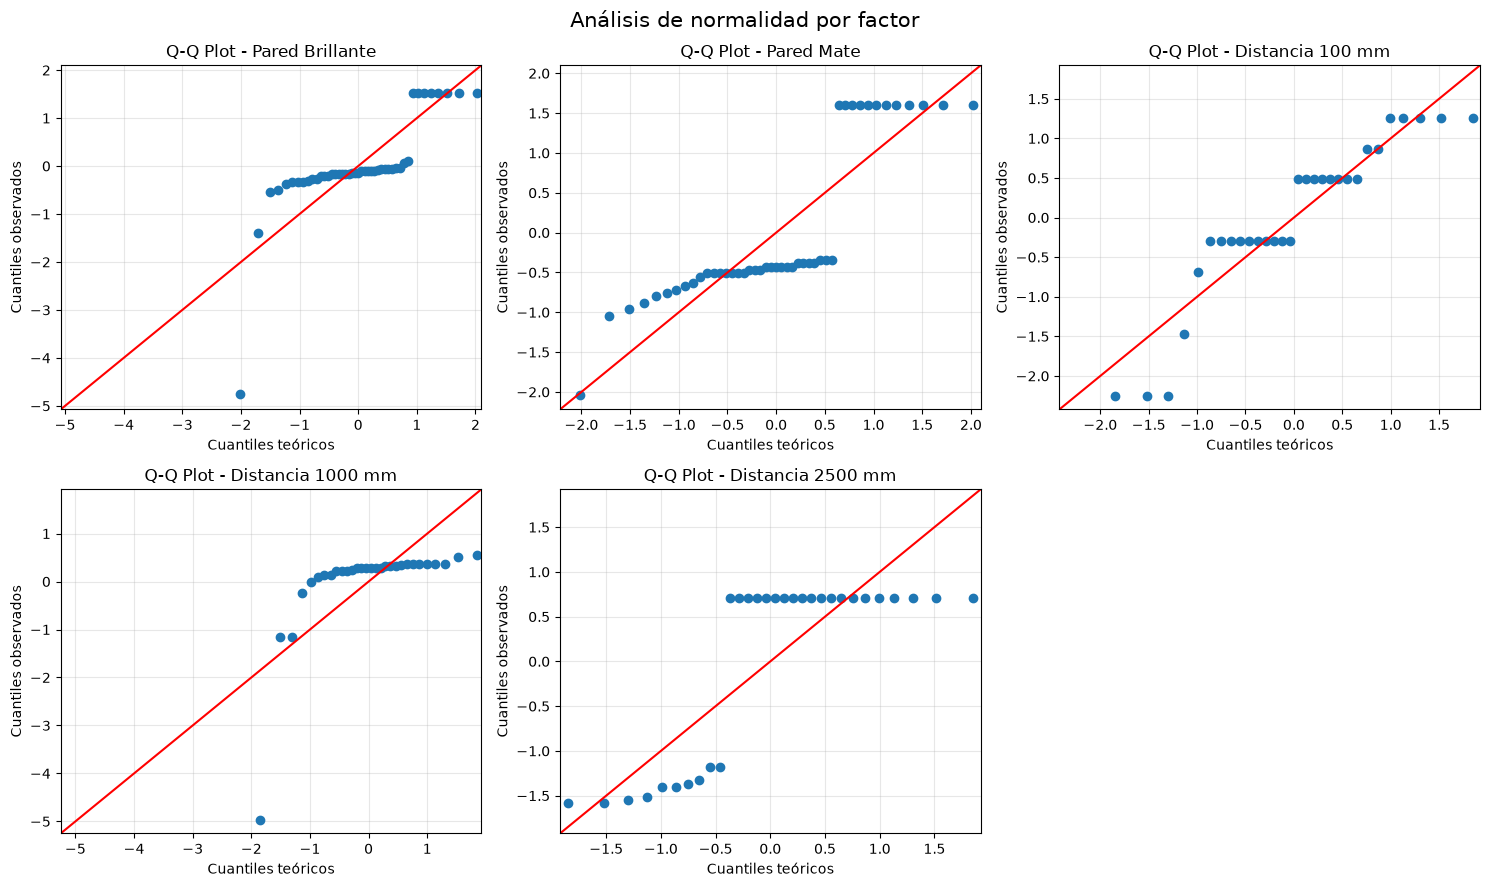

In [32]:
# datos_qq = {
#     "Pared brillante": datos_brillante,
#     "Pared mate": datos_mate,
#     "Distancia 100 mm": datos_dist_100,
#     "Distancia 1000 mm": datos_dist_1000,
#     "Distancia 2500 mm": datos_dist_2500
# }

datos_qq = datos

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (nombre, valores) in enumerate(datos_qq.items()):
    sm.qqplot(
        valores.dropna(),
        line="45",
        fit=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Q-Q Plot - {nombre}")
    axes[i].set_xlabel("Cuantiles teóricos")
    axes[i].set_ylabel("Cuantiles observados")
    axes[i].grid(alpha=0.3)

axes[5].axis("off")

plt.suptitle("Análisis de normalidad por factor", fontsize=15)
plt.tight_layout()
plt.show()

No se observan muy normales, por lo que se generan gráficos con la transformación.

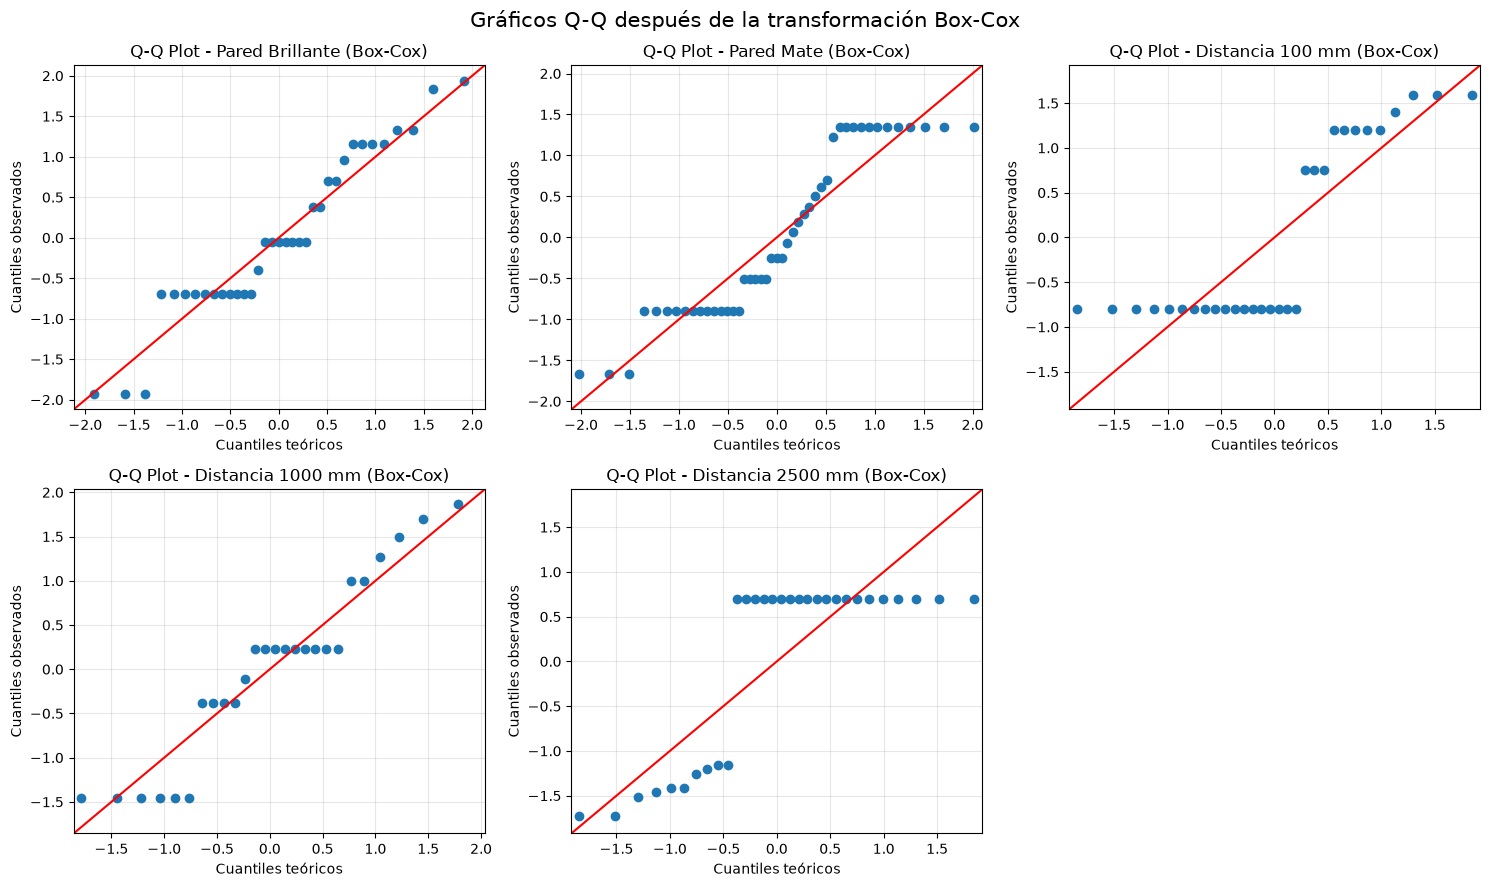

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (grupo, valores) in enumerate(datos_transformados_por_grupo.items()):
    sm.qqplot(
        valores,
        line="45",
        fit=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Q-Q Plot - {grupo} (Box-Cox)")
    axes[i].set_xlabel("Cuantiles teóricos")
    axes[i].set_ylabel("Cuantiles observados")
    axes[i].grid(alpha=0.3)

# Ocultar gráficos vacíos
for j in range(len(datos_transformados_por_grupo), len(axes)):
    axes[j].axis("off")

plt.suptitle("Gráficos Q-Q después de la transformación Box-Cox", fontsize=15)
plt.tight_layout()
plt.show()

Ya con la transformación, los gráficos se ven un poco más nromales, a excepción de la distancia 2500 milímetros y la pared mate.

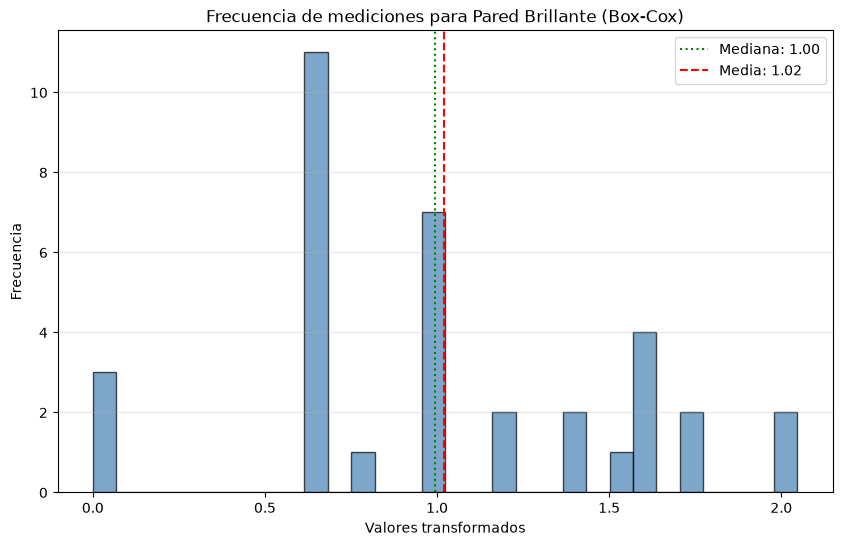

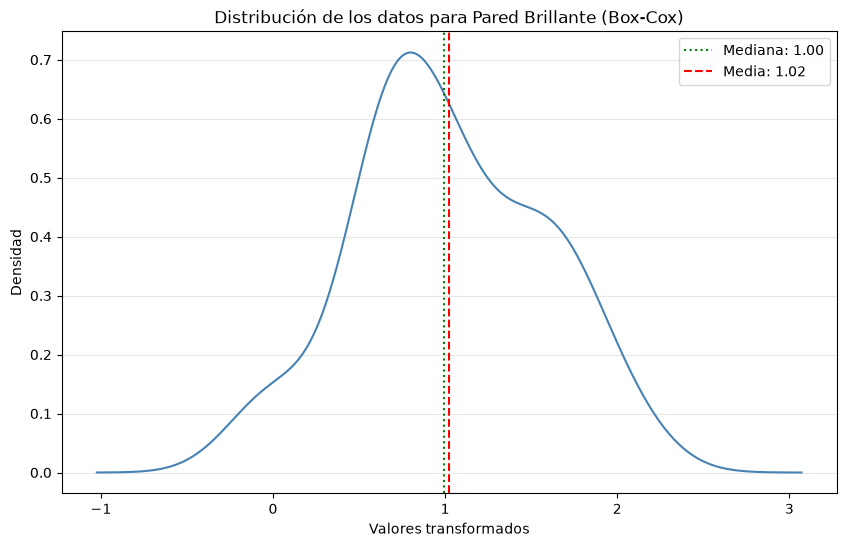

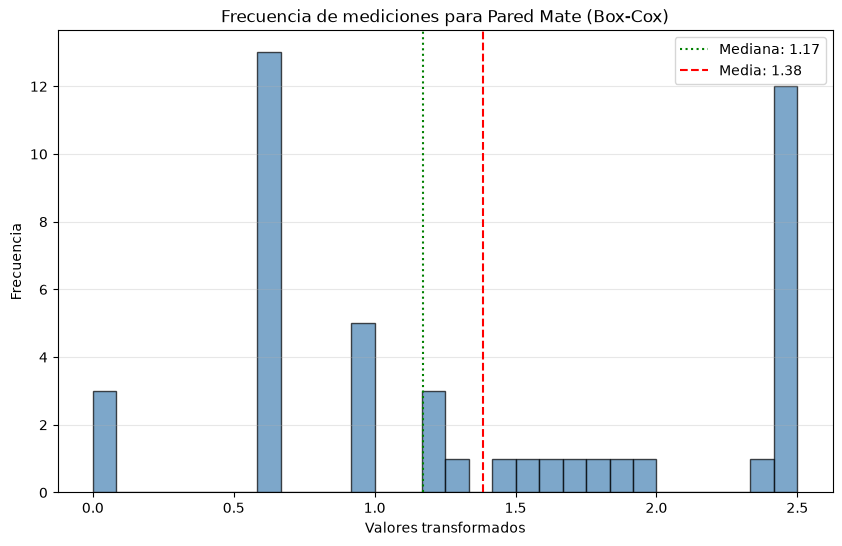

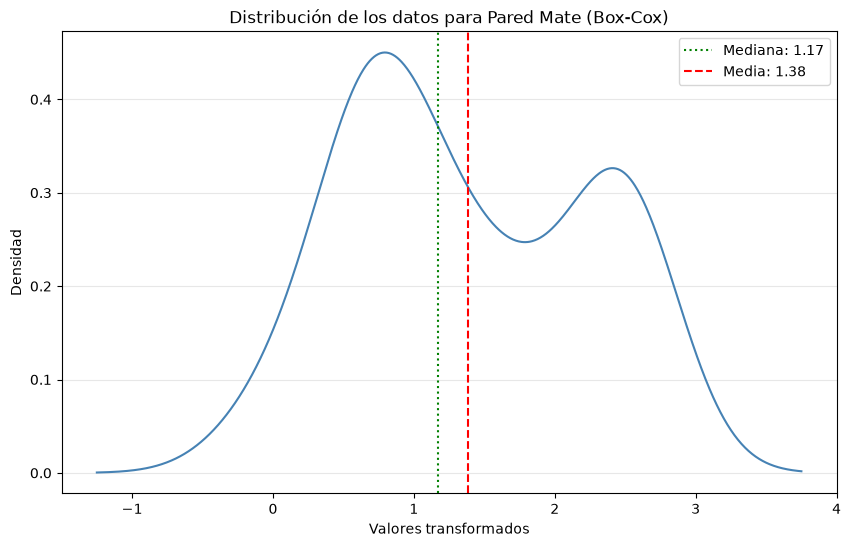

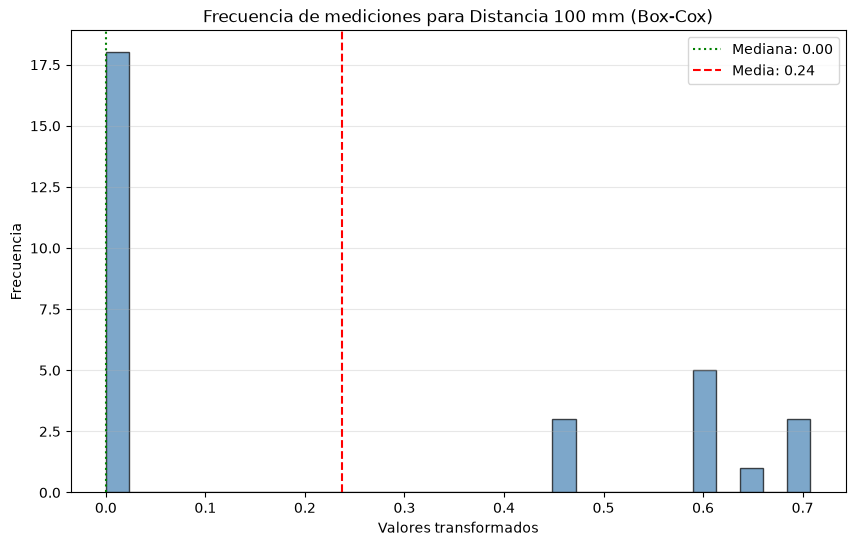

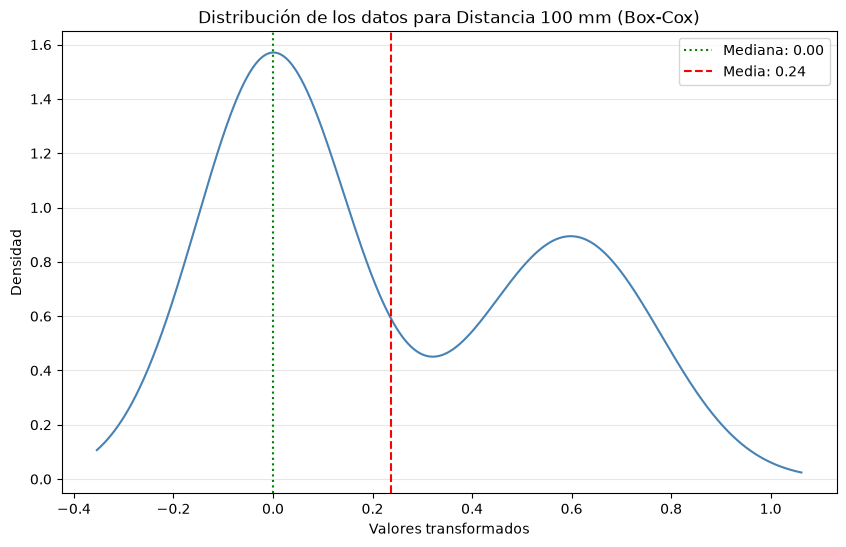

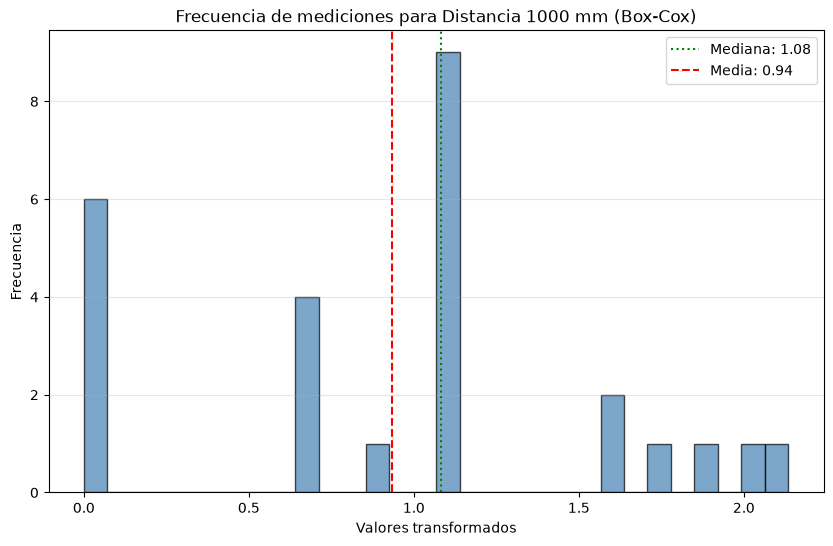

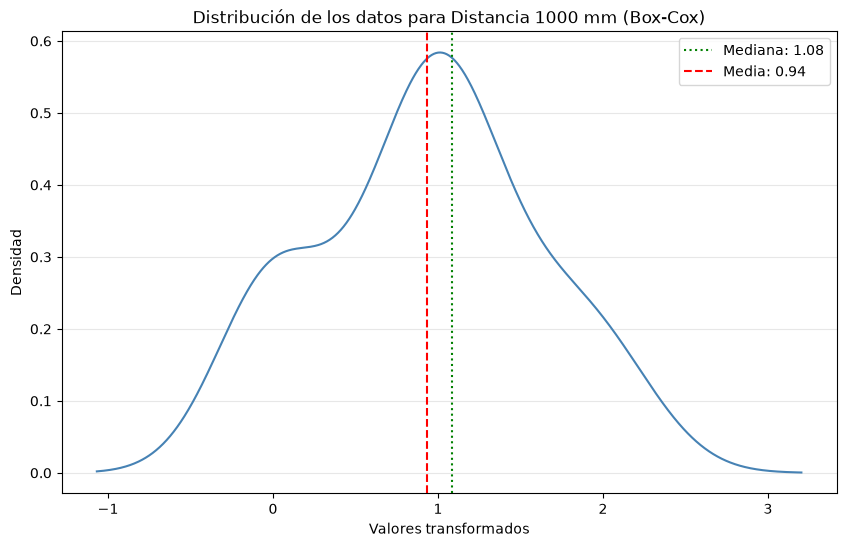

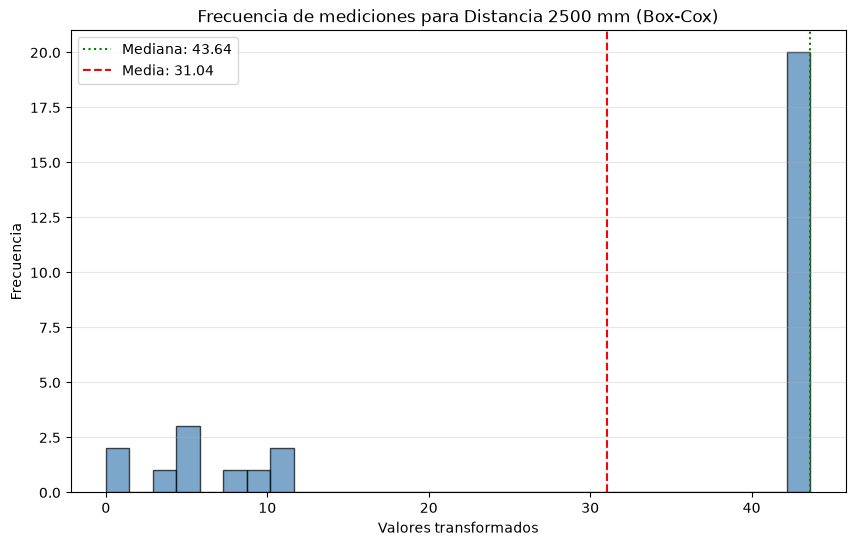

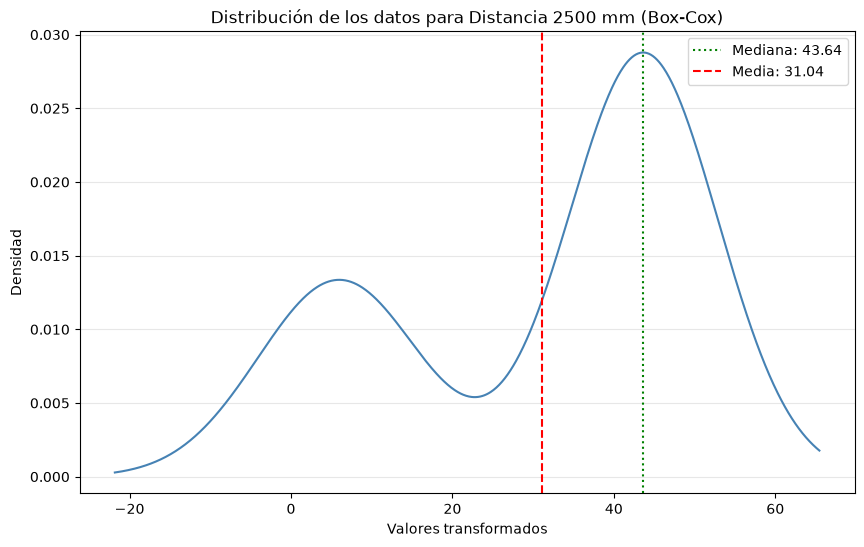

In [34]:
for grupo, valores in datos_transformados_por_grupo.items():
    plt.figure(figsize=(10, 6))
    plt.hist(
        valores,
        bins=30,
        color="steelblue",
        edgecolor="black",
        alpha=0.7
    )
    plt.axvline(
        np.median(valores),
        linestyle=":",
        color="green",
        label=f"Mediana: {np.median(valores):,.2f}"
    )
    plt.axvline(
        np.mean(valores),
        linestyle="--",
        color="red",
        label=f"Media: {np.mean(valores):,.2f}"
    )
    plt.title(f"Frecuencia de mediciones para {grupo} (Box-Cox)")
    plt.xlabel("Valores transformados")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    # Distribución de los datos para pared brillante
    valores_series = pd.Series(valores)
    valores_series.plot(kind="density", figsize=(10, 6), color="steelblue")
    plt.axvline(
        np.median(valores),
        linestyle=":",
        color="green",
        label=f"Mediana: {np.median(valores):,.2f}"
    )
    plt.axvline(
        np.mean(valores),
        linestyle="--",
        color="red",
        label=f"Media: {np.mean(valores):,.2f}"
    )
    plt.title(f"Distribución de los datos para {grupo} (Box-Cox)")
    plt.xlabel("Valores transformados")
    plt.ylabel("Densidad")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.show()

## Principales hallazgos del EDA

Con los gráficos y la estadística descriptiva se puede observar que las mediciones presentan errores absolutos más grandes a distancias mayores, principalmente a 2500 milímetros. Las diferencias entre las superficies no mantienen el mismo comportamiento en todas las distancias: en 100 y 1000 milímetros el error promedio es mayor en la pared brillante, mientras que en 2500 milímetros es mayor en la pared mate.

Los boxplots y diagramas de desviación estándar permiten observar diferencias en la dispersión de las mediciones entre tratamientos. En particular, la pared brillante a 1000 milímetros presenta una variabilidad alta. Las pruebas de Shapiro-Wilk realizadas sobre los cinco grupos originales rechazan la normalidad, y la prueba de Levene aplicada a las seis combinaciones rechaza la homogeneidad de varianzas. Con la transformación Box-Cox se mejora la normalidad en algunos grupos, pero no en todos.

Estos resultados permiten identificar tendencias y posibles problemas en los supuestos estadísticos. Sin embargo, el EDA por sí solo no permite confirmar que la distancia o el tipo de pared tengan un efecto estadísticamente significativo sobre la exactitud del sensor.